# Binary expression and morphology: methods laboratory

A companion to [joint_morphology_expression_tutorial.ipynb](joint_morphology_expression_tutorial.ipynb), created 9 October 2026. This is a **new exploratory analysis**, not a reproduction of its saved projections. Run top to bottom using **Python (MorphoFeats_dev)**.

**Prerequisites:** the same binary spatial table, explicit cell↔nucleus mapping, original DINO NPZ, historical MorphoFeatures NPY, manual labels, nucleus positions and bilateral table used by the source notebook; NumPy, pandas, SciPy, scikit-learn, matplotlib and threadpoolctl. UMAP is optional. No raw sequencing reference, GPU, training job or extra package installation is needed. Files below are actual local inputs, not portable example paths.

**The central distinction:** your EM-linked data are registered **binary spatial gene calls**, not counts from sequencing those EM cells. The source notebook reports 11,382 nuclei × 201 genes, with five all-zero rows; we re-audit this below. Its separate 31,121-cell scRNA reference has different identities. Neither its counts nor its sequencing batches can be assigned to the EM cells by row position.

This notebook asks: *Which expression geometry is useful, and how does the choice affect its combination with morphology?* It provides executable baselines, matched-cohort plots, diagnostic tables, and manual-label cross-validation. It does not use scLocator's expression-derived assignments as independent truth.

Start with the defaults: full-cohort vector fits and **1,500 uniformly sampled cells** for quadratic distance/graph/visualization work; all eligible manual annotations for cross-validation. Outputs are isolated in `outputs/exploration/binary_expression_methods/<run>/`. Plotting and graph results are transductive; classifier transforms are fitted separately inside each training fold.

## 1. Why the data type changes the analysis

For raw UMI counts, observed variability depends on abundance and library size. Common workflows use count QC, size-factor normalization/log1p and variable genes, or count-model Pearson residuals followed by PCA; scVI offers a count-likelihood latent model when adequate counts, batches and cells are available. These choices address the count-generating process. [Scanpy count workflow](https://scanpy.scverse.org/en/stable/tutorials/basics/clustering.html), [Pearson residuals](https://scanpy.scverse.org/en/stable/tutorials/experimental/pearson_residuals.html), [scVI inputs](https://docs.scvi-tools.org/en/stable/tutorials/notebooks/quick_start/api_overview.html).

For a binary call $x_{ig}\in\{0,1\}$, molecule abundance has been discarded. `log1p(x)` merely multiplies every 1 by log(2). The number of positive calls is **not sequencing library size**: it may reflect biology, registration, thresholds or assay coverage. Zeros are recorded negatives, not proof of biological absence; missing measurements must not silently become zeros. Do not run SCTransform, count Pearson residuals or a negative-binomial scVI model on this spatial binary panel as if it contained UMI counts.

PCA is still a valid least-squares projection of binary data; it does **not** require normally distributed inputs to compute useful components. Its objective and geometry differ from a Bernoulli model. Unscaled PCA emphasizes genes with larger variance $p_g(1-p_g)$; z-scoring divides by $\sqrt{p_g(1-p_g)}$ and can give rare, noisy calls much more influence. With only 201 selected genes, generic top-2,000-HVG selection is inappropriate.

Keep three decisions separate: **representation** (binary/PCA/LSI), **integration** (vectors/distances/graphs), and **display** (PCA/UMAP/t-SNE/spectral coordinates). A 2D display is not the feature space used for prediction.

| Method | What it regards as similar | Role here / limitation |
|---|---|---|
| Hamming / binary Euclidean | Few mismatching calls; shared zeros count as agreement | Transparent baseline; common negatives can dominate. For a fixed panel, squared Euclidean = number of mismatches. |
| Jaccard | Large intersection relative to union of positive calls | Good first sensitivity check when shared absences are weak evidence; unstable for few positives and rich in tied distances. |
| Positive-call cosine | Overlap relative to each cell's positive-call count | Does not count shared zeros; compares direction, not burden. |
| Centered, row-normalized binary + PCA | Deviations from gene prevalence, with cell direction normalized | Reuses the source notebook's expression baseline. |
| Raw binary PCA / standardized PCA | Covariance / equal marginal variance | Compare both; rare-gene scaling is a modeling choice. |
| TF–IDF + truncated SVD (LSI) | Downweights widespread calls, then finds latent directions | Inspired by sparse accessibility/text workflows; a sensitivity analysis for a small marker panel, not an established default for these spatial calls. |
| Bernoulli factors / logistic PCA | Low-rank model of positive-call probabilities | Statistically suited to binary likelihoods; tune rank/regularization with held-out Bernoulli deviance. Discussed below, not fitted here. |

Jaccard is $1-|A\cap B|/|A\cup B|$; shared zeros do not enter its denominator. Its all-zero convention is a numerical convention, not biological similarity. [SciPy definition](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.jaccard.html).

A useful simplification: Hellinger-transforming a binary row gives $\sqrt{x/\sum x}=x/\sqrt{\sum x}$, exactly its L2-normalized positive-call vector. Thus Hellinger and positive-call cosine give the same neighbor ranking here (before any further dimensionality reduction). They are not two independent methods to benchmark.

In [9]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from decimal import Decimal
import os, json, hashlib, platform, re, importlib.metadata as metadata

REPO = Path('/g/kreshuk/frazer/projects/MorphoFeatures')
SOURCE_NOTEBOOK = REPO / 'joint_morphology_expression_tutorial.ipynb'
EXPRESSION_PATH = Path('/g/kreshuk/frazer/data/platy_data/expression/sclocator/spatial_expr_df_binarized.tsv')
CELL_TABLE_ROOT = Path('/g/kreshuk/mansaray/platy_data/1.0.1/tables/sbem-6dpf-1-whole-segmented-cells')
NUCLEUS_PATH = CELL_TABLE_ROOT.parent / 'sbem-6dpf-1-whole-segmented-nuclei/default.tsv'
DINO_PATH = REPO / 'outputs/experiments/DinoV2-b-reg-embedding-label-transfer-platy-par/workspace/00-transfer/reference/original_embeddings.npz'
MORPHO_PATH = REPO / 'analysis/data/morphofeatures_all_cells.npy'
MANUAL_PATH = REPO / 'analysis/data/class_labels.tsv'

SEED = 42
CPU_THREADS = 2
MAX_GEOMETRY_CELLS = 100000  # Same random sample/search population for every distance and layout.
MAX_DISTANCE_GIB = 100  # Conservative estimate for retained matrices + temporary work.
LATENT_DIM = 200  # Compare 15/30/50 in separate runs; not tuned on reported labels.
N_NEIGHBORS = 20
EXPRESSION_WEIGHTS = (0.25, 0.50, 0.75)
MORPHOLOGY_FOR_FUSION = 'DINO'  # Or 'MorphoFeatures'; both appear as standalone baselines.
EXPRESSION_VECTOR_METHODS = ('tutorial', 'binary_pca', 'zscore_pca', 'positive_svd', 'tfidf_lsi')
LSI_DROP_FIRST = False  # Inspect burden correlations before deciding to remove a component.
UMAP_NAMES = ('DINO', 'MorphoFeatures', 'E_tutorial', 'E_jaccard', 'E_tfidf_lsi', 'joint_jaccard_0.50')
RUN_UMAP = True
RUN_LAYOUT_SENSITIVITY = True  # Seed and neighborhood/min_dist variants of joint Jaccard.
RUN_TSNE = False  # Extra display of the same joint dissimilarity; slower.
RUN_CLASSIFICATION = True
CLASSIFIER_FOLDS = 3
SPATIAL_REGIONS = 12
LOGISTIC_C = 10.0
CV_EXPRESSION_METHODS = ('tutorial', 'binary_pca', 'tfidf_lsi')
CV_WEIGHTS = (0.50,)  # Expand explicitly; more comparisons need independent confirmation.

RUN_ID = datetime.now(ZoneInfo('Europe/Berlin')).strftime('%Y%m%d-%H%M%S-%f')
OUT = REPO / 'outputs/exploration/binary_expression_methods' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
for folder in ('tables', 'figures', 'vectors', 'graphs', 'models'):
    (OUT / folder).mkdir()
os.environ.setdefault('MPLCONFIGDIR', str(OUT / '.matplotlib'))
os.environ.setdefault('NUMBA_NUM_THREADS', str(CPU_THREADS))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import SpectralEmbedding, trustworthiness, TSNE
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(CPU_THREADS)
plt.rcParams.update({'figure.facecolor': 'white', 'axes.spines.top': False,
                     'axes.spines.right': False, 'svg.fonttype': 'none'})

def slug(x): return re.sub(r'[^a-z0-9]+', '_', x.lower()).strip('_')
def table(df, name): df.to_csv(OUT / 'tables' / f'{name}.tsv', sep='\t', index=False)
def write_json(x, path):
    Path(path).write_text(json.dumps(x, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)))
def figure(fig, name):
    for ext in ('png', 'svg'):
        fig.savefig(OUT / 'figures' / f'{name}.{ext}', dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024**2), b''): h.update(block)
    return h.hexdigest()

versions = {}
for pkg in ('numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'threadpoolctl', 'umap-learn'):
    try: versions[pkg] = metadata.version(pkg)
    except metadata.PackageNotFoundError: versions[pkg] = None
if RUN_UMAP and versions['umap-learn'] is None:
    raise ImportError('Select MorphoFeats_dev or set RUN_UMAP=False; other analyses do not require UMAP.')
assert MORPHOLOGY_FOR_FUSION in ('DINO', 'MorphoFeatures')
assert all(0 < w < 1 for w in (*EXPRESSION_WEIGHTS, *CV_WEIGHTS))
print('Output:', OUT)
print('Versions:', versions)

Output: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/binary_expression_methods/20261009-135558-971190
Versions: {'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1', 'threadpoolctl': '3.6.0', 'umap-learn': '0.5.12'}


## 2. Rebuild the identity-safe cohort and audit binary calls

Expression IDs are nuclei; embedding IDs are cells. We join through `cells_to_nuclei.tsv`, validate uniqueness, exclude missing modalities and all-zero expression rows, and save the complete inclusion audit. The legacy NPY has cell IDs in its first column: these are removed from its features. Spatial coordinates are nucleus anchors, with explicit X/Y/Z column names, in the source table frame; no conversion to voxel indices is made. Confirm physical units/registration metadata before physical-distance analyses.

Constant genes are recorded and removed **inside each fitted transform**. Direct binary distances use the full supplied panel. An all-zero constant gene rescales Hamming's denominator but does not change its neighbor ranking; all-one genes would alter Jaccard and deserve a separate sensitivity analysis.

Input: (11382, 201); matched nonempty cohort: 11,377; annotated: 390
Excluded: {'all_zero': 5}
Unmapped expression nuclei: 0
Unique binary profiles: 11298 ; fraction of cells in repeated profiles: 0.012129735431132988


,gene,positive_cells,prevalence,constant
85,XLOC-019991,0.0,0.0,True


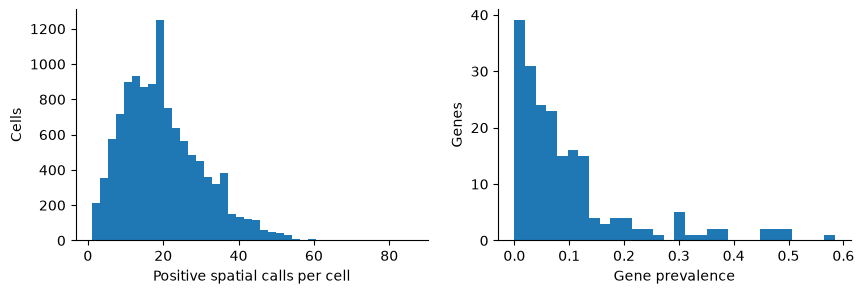

In [4]:
def exact_ids(values, name='ID'):
    out = []
    for value in values:
        if isinstance(value, (float, np.floating)) and (not np.isfinite(value) or abs(value) >= 2**53):
            raise ValueError(f'{name}: floating identity is not safely recoverable: {value!r}')
        n = Decimal(str(value))
        if not n.is_finite() or n != n.to_integral_value() or n < 0 or n > np.iinfo(np.int64).max:
            raise ValueError(f'{name}: expected exact nonnegative int64 identity, got {value!r}')
        out.append(int(n))
    return np.asarray(out, dtype=np.int64)

def id_table(path, column='label_id'):
    f = pd.read_csv(path, sep='\t', dtype={column: str})
    f[column] = exact_ids(f[column], column)
    if f[column].duplicated().any(): raise ValueError(f'Duplicate {column}: {path}')
    return f.set_index(column)

def load_npz(path):
    with np.load(path, allow_pickle=False) as f:
        ix, X = exact_ids(f['label_ids']), f['features'].copy()
    if X.ndim != 2 or len(ix) != len(X) or len(np.unique(ix)) != len(ix) or not np.isfinite(X).all():
        raise ValueError(f'Invalid embedding table: {path}')
    return pd.DataFrame(X, index=pd.Index(ix, name='cell_id'))

def align_expression(expr, mapping):
    if not expr.index.is_unique or not mapping.index.is_unique or not mapping.nucleus_id.is_unique:
        raise ValueError('Expected unique one-to-one cell/nucleus identities.')
    common = mapping.index[mapping.nucleus_id.isin(expr.index)]
    out = expr.loc[mapping.loc[common, 'nucleus_id'].to_numpy()].copy()
    out.index = pd.Index(common, name='cell_id')
    return out

expr_n = id_table(EXPRESSION_PATH).rename_axis('nucleus_id')
if not np.isin(expr_n.to_numpy(), [0, 1]).all():
    raise ValueError('Expected observed 0/1 calls, without missing values. Do not fill missing calls with zero.')
expr_n = expr_n.astype(np.uint8)
mapping = pd.read_csv(CELL_TABLE_ROOT / 'cells_to_nuclei.tsv', sep='\t', dtype=str)
mapping['label_id'] = exact_ids(mapping.label_id)
mapping['nucleus_id'] = exact_ids(mapping.nucleus_id)
if mapping.label_id.duplicated().any(): raise ValueError('Duplicate cell mapping.')
mapping = mapping.set_index('label_id').rename_axis('cell_id')
mapping = mapping.loc[mapping.nucleus_id.ne(0)]
expr = align_expression(expr_n, mapping)
missing_nuclei = expr_n.index.difference(mapping.nucleus_id)
table(pd.DataFrame({'nucleus_id': missing_nuclei}), 'expression_nuclei_without_cell_mapping')
dino = load_npz(DINO_PATH)
legacy = np.load(MORPHO_PATH, mmap_mode='r', allow_pickle=False)
if legacy.ndim != 2 or legacy.shape[1] < 2: raise ValueError('Expected ID + features in historical NPY.')
morpho = pd.DataFrame(np.array(legacy[:, 1:]), index=pd.Index(exact_ids(legacy[:, 0]), name='cell_id'))
if not morpho.index.is_unique or not np.isfinite(morpho.to_numpy()).all(): raise ValueError('Invalid MorphoFeatures.')
manual = id_table(MANUAL_PATH)['cell_type']
all_ids = expr.index.union(dino.index).union(morpho.index).sort_values()
audit = pd.DataFrame(index=all_ids.rename('cell_id'))
audit['nucleus_id'] = mapping.nucleus_id.reindex(all_ids).astype('Int64')
for name, f in [('expression', expr), ('DINO', dino), ('MorphoFeatures', morpho)]:
    audit['has_' + name] = all_ids.isin(f.index)
audit['positive_calls'] = expr.sum(axis=1).reindex(all_ids)
audit['included'] = audit[['has_expression', 'has_DINO', 'has_MorphoFeatures']].all(axis=1) & audit.positive_calls.gt(0)
audit['reason'] = np.where(audit.included, 'included', np.where(audit.positive_calls.eq(0), 'all_zero', 'missing_modality'))
table(audit.reset_index(), 'cohort_audit')
ids = audit.index[audit.included]
nucleus_ids = mapping.loc[ids, 'nucleus_id'].to_numpy(dtype=np.int64)
E = expr.loc[ids].to_numpy(dtype=float)
X_morph = {'DINO': dino.loc[ids].to_numpy(dtype=float), 'MorphoFeatures': morpho.loc[ids].to_numpy(dtype=float)}
assert np.array_equal(E, expr_n.loc[nucleus_ids].to_numpy())
labels = manual.reindex(ids)
nucleus_table = id_table(NUCLEUS_PATH)
XYZ = nucleus_table.reindex(nucleus_ids)[['anchor_x', 'anchor_y', 'anchor_z']].to_numpy(dtype=float)
if not np.isfinite(XYZ).all(): raise ValueError('Missing nucleus anchors: repair spatial metadata before validation.')
gene_qc = pd.DataFrame({'gene': expr.columns, 'positive_cells': E.sum(0), 'prevalence': E.mean(0), 'constant': np.ptp(E, axis=0) == 0})
table(gene_qc, 'gene_qc')
_, profile_counts = np.unique(E, axis=0, return_counts=True)
print(f'Input: {expr_n.shape}; matched nonempty cohort: {len(ids):,}; annotated: {labels.notna().sum()}')
print('Excluded:', audit.loc[~audit.included, 'reason'].value_counts().to_dict())
print('Unmapped expression nuclei:', len(missing_nuclei))
print('Unique binary profiles:', len(profile_counts), '; fraction of cells in repeated profiles:', profile_counts[profile_counts > 1].sum()/len(E))
display(gene_qc.loc[gene_qc.constant])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(E.sum(1), bins=40); ax[0].set(xlabel='Positive spatial calls per cell', ylabel='Cells')
ax[1].hist(E.mean(0), bins=30); ax[1].set(xlabel='Gene prevalence', ylabel='Genes')
figure(fig, 'binary_qc')

## 3. Fit comparable expression vectors

`ExpressionMap` exposes five trainable recipes. `tutorial` reproduces the source's centered, row-L2-normalized expression block, followed here by a separate expression PCA. `binary_pca` centers raw calls without prior row normalization. `zscore_pca` additionally scales each gene to unit training variance. `positive_svd` compresses the positive-call unit vectors without centering. `tfidf_lsi` uses:

$$TF_{ig}=x_{ig}/\sum_gx_{ig},\quad IDF_g=\log(1+n/(1+df_g)),\quad Z_{ig}=\log(1+10^4 TF_{ig}IDF_g).$$

Then truncated SVD gives the latent scores. `df`, the variable-gene mask and SVD are learned on training cells. The `+1` in document frequency is explicit smoothing. This is a stated **Signac-inspired variant**, not an exact reproduction of a Signac default. TF–IDF conventions differ between implementations; record the formula, not only “LSI.” [Signac TF–IDF options](https://stuartlab.org/signac/reference/runtfidf).

Every vector method keeps up to `LATENT_DIM` dimensions, without PC whitening. For joint vectors, each latent block is subsequently divided by its training RMS distance from its centroid. This balances total variance while preserving within-block relative distances. It is different from the source's row normalization after centering. The `tutorial` full-vector baseline below preserves that original pre-PCA block recipe for direct comparison.

Inspect retained variance and component–burden correlations. **Do not automatically drop LSI1 or regress out positive-call burden**: either may contain real biology. Explained-variance fractions refer to different transformed matrices and are not a common accuracy score.

In [7]:
class ExpressionMap:
    def __init__(self, method='binary_pca', n_components=LATENT_DIM, drop_first=LSI_DROP_FIRST):
        self.method, self.n_components, self.drop_first = method, n_components, drop_first
    def _input(self, X):
        X = np.asarray(X, dtype=float)[:, self.keep_]
        if self.method == 'tutorial': return normalize(X - self.mean_)
        if self.method == 'zscore_pca': return (X - self.mean_) / self.std_
        if self.method == 'positive_svd': return normalize(X)
        if self.method == 'tfidf_lsi':
            tf = X / np.maximum(X.sum(1, keepdims=True), 1)
            return np.log1p(1e4 * tf * self.idf_)
        if self.method == 'binary_pca': return X
        raise ValueError(self.method)
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if not np.isin(X, [0, 1]).all(): raise ValueError('ExpressionMap requires binary observed values.')
        self.keep_ = np.ptp(X, axis=0) > 0
        if not self.keep_.any(): raise ValueError('No variable expression genes in fitting cohort.')
        A = X[:, self.keep_]
        self.mean_, self.std_ = A.mean(0), A.std(0)
        self.idf_ = np.log1p(len(X) / (1 + A.sum(0)))
        self.offset_ = int(self.method == 'tfidf_lsi' and self.drop_first)
        dim = min(self.n_components + self.offset_, len(X)-1, A.shape[1])
        if dim <= self.offset_: raise ValueError('Insufficient rank for requested representation.')
        cls = TruncatedSVD if self.method in ('positive_svd', 'tfidf_lsi') else PCA
        self.reducer_ = cls(n_components=dim, random_state=SEED, **({'svd_solver':'randomized'} if cls is PCA else {}))
        self.reducer_.fit(self._input(X))
        return self
    def transform(self, X): return self.reducer_.transform(self._input(X))[:, self.offset_:]
    def fit_transform(self, X): return self.fit(X).transform(X)

class MorphologyMap:
    def fit(self, X):
        self.keep_ = np.ptp(X, axis=0) > 0
        if not self.keep_.any(): raise ValueError('No variable morphology features.')
        self.mean_ = X[:, self.keep_].mean(0)
        A = normalize(X[:, self.keep_] - self.mean_)
        self.reducer_ = PCA(n_components=min(LATENT_DIM, len(X)-1, A.shape[1]), svd_solver='randomized', random_state=SEED).fit(A)
        return self
    def transform(self, X): return self.reducer_.transform(normalize(X[:, self.keep_] - self.mean_))
    def fit_transform(self, X): return self.fit(X).transform(X)

class RMSBlock:
    def fit(self, X):
        self.mean_ = X.mean(0)
        self.scale_ = float(np.sqrt(np.mean(np.sum((X - self.mean_)**2, axis=1))))
        if self.scale_ < 1e-12: raise ValueError('Degenerate latent block.')
        return self
    def transform(self, X): return (X - self.mean_) / self.scale_
    def fit_transform(self, X): return self.fit(X).transform(X)

class TutorialBlock:
    def fit(self, X):
        self.keep_ = np.ptp(X, axis=0) > 0
        if not self.keep_.any(): raise ValueError('No variable features.')
        self.mean_ = X[:, self.keep_].mean(0)
        return self
    def transform(self, X): return normalize(X[:, self.keep_] - self.mean_)

vectors, raw_latents, fit_models, diagnostics, loading_rows = {}, {}, {}, [], []
for name, X in X_morph.items():
    model = MorphologyMap()
    raw_latents[name] = model.fit_transform(X)
    balance = RMSBlock()
    vectors[name] = balance.fit_transform(raw_latents[name])
    fit_models[name] = (model, balance)
for method in EXPRESSION_VECTOR_METHODS:
    name = 'E_' + method
    model = ExpressionMap(method)
    raw_latents[name] = model.fit_transform(E)
    balance = RMSBlock()
    vectors[name] = balance.fit_transform(raw_latents[name])
    fit_models[name] = (model, balance)
    for pc, weights in enumerate(model.reducer_.components_[model.offset_:]):
        for gene, weight in zip(expr.columns[model.keep_], weights):
            loading_rows.append({'method': method, 'component': pc+1, 'gene': gene, 'loading': weight})
for name, Z in raw_latents.items():
    model = fit_models[name][0]
    offset = getattr(model, 'offset_', 0)
    for pc in range(Z.shape[1]):
        rho = spearmanr(Z[:, pc], E.sum(1)).statistic if np.std(Z[:, pc]) > 1e-12 else np.nan
        diagnostics.append({'representation': name, 'component': pc+1, 'burden_spearman': rho,
                            'explained_variance_ratio': model.reducer_.explained_variance_ratio_[pc+offset]})
for method in EXPRESSION_VECTOR_METHODS:
    for w in EXPRESSION_WEIGHTS:
        vectors[f'joint_{method}_{w:.2f}'] = np.column_stack([
            np.sqrt(1-w)*vectors[MORPHOLOGY_FOR_FUSION], np.sqrt(w)*vectors['E_'+method]])
# The source's full-vector balanced-block recipe, without a new PCA truncation.
full_m = TutorialBlock().fit(X_morph[MORPHOLOGY_FOR_FUSION]).transform(X_morph[MORPHOLOGY_FOR_FUSION])
full_e = TutorialBlock().fit(E).transform(E)
vectors['tutorial_full_joint_0.50'] = np.column_stack([np.sqrt(.5)*full_m, np.sqrt(.5)*full_e])
for name, Z in vectors.items():
    np.savez_compressed(OUT/'vectors'/f'{slug(name)}.npz', label_ids=ids.to_numpy(np.int64), nucleus_ids=nucleus_ids, features=Z.astype(np.float32))
for name, (model, balance) in fit_models.items():
    arrays = {key: value for key, value in vars(model).items() if isinstance(value, np.ndarray)}
    arrays.update(components=model.reducer_.components_, reducer_mean=getattr(model.reducer_, 'mean_', np.zeros(model.reducer_.components_.shape[1])),
                  balance_mean=balance.mean_, balance_scale=balance.scale_, offset=getattr(model, 'offset_', 0))
    np.savez_compressed(OUT/'models'/f'{slug(name)}_descriptive.npz', **arrays)
diag = pd.DataFrame(diagnostics)
table(diag, 'latent_diagnostics'); table(pd.DataFrame(loading_rows), 'expression_loadings')
display(diag.groupby('representation').agg(dimensions=('component', 'size'), retained_variance=('explained_variance_ratio','sum'), max_abs_burden_rho=('burden_spearman', lambda x: x.abs().max())).round(3))

,dimensions,retained_variance,max_abs_burden_rho
representation,,,
DINO,200,0.997,0.228
E_binary_pca,200,1.000,0.647
E_positive_svd,200,1.000,0.633
E_tfidf_lsi,200,1.000,0.817
E_tutorial,200,1.000,0.709
E_zscore_pca,200,1.000,0.638
MorphoFeatures,200,0.980,0.280


## 4. Compare binary neighborhoods and fuse distances

A fixed, uniformly sampled cohort bounds $O(n^2)$ storage and computation. Every displayed method searches exactly this population, so these neighbors are **not full-atlas nearest neighbors**. The sampled cell IDs are exported. Full-cohort vector fits above remain descriptive, while classification below uses all eligible annotations and independent fits.

We compare Hamming, Jaccard and positive-call cosine on the original calls, alongside latent Euclidean distances. For distance fusion, each modality's distance matrix is divided by its median positive off-diagonal distance on this same sample:

$$d_{joint}=\sqrt{(1-w)(d_M/s_M)^2+w(d_E/s_E)^2}.$$

This preserves each modality's geometry up to scaling; `w` controls squared-distance contributions. Median-distance weighting differs from the RMS vector weighting above, so a distance/vector difference is not attributable solely to Jaccard. We also export Euclidean-expression distance fusions with the same normalization as a control. A Jaccard joint dissimilarity need not be Euclidean; it is used as a dissimilarity, not interpreted as a concatenated feature vector.

Repeated profiles and discrete distances create ties. Neighbor diagnostics break ties reproducibly by a seeded random ordering of cell IDs, and report the fraction of cells whose kth neighbor lies on a tie. Exact identities inside a tied neighborhood are not evidence of biological precision.

In [10]:
rng = np.random.default_rng(SEED)
subset = np.sort(rng.choice(len(ids), size=min(MAX_GEOMETRY_CELLS, len(ids)), replace=False))
gids, gnuc = ids.to_numpy()[subset], nucleus_ids[subset]
n = len(subset)
k = min(N_NEIGHBORS, (n-1)//2)
if k < 2: raise ValueError('Need at least five cells for geometry diagnostics.')
estimated_gib = (len(vectors) + 3 + 2*len(EXPRESSION_WEIGHTS) + 8) * n*n*8 / 2**30
if estimated_gib > MAX_DISTANCE_GIB:
    raise MemoryError(f'Estimated distance working set {estimated_gib:.2f} GiB; lower MAX_GEOMETRY_CELLS or raise budget explicitly.')
table(pd.DataFrame({'cell_id': gids, 'nucleus_id': gnuc}), 'geometry_cohort')

def pairdist(X, metric='euclidean'):
    d = squareform(pdist(X, metric=metric))
    np.fill_diagonal(d, 0)
    if not np.isfinite(d).all(): raise ValueError(f'Nonfinite {metric} distances; inspect empty profiles.')
    return d

distances = {name: pairdist(Z[subset]) for name, Z in vectors.items()}
for name, metric in [('E_jaccard','jaccard'), ('E_hamming','hamming'), ('E_positive_cosine','cosine')]:
    distances[name] = pairdist(E[subset].astype(bool) if metric != 'cosine' else E[subset], metric)

def unit_distance(d):
    upper = d[np.triu_indices(len(d), 1)]
    positive = upper[upper > 0]
    if not len(positive): raise ValueError('All pairwise distances are zero.')
    scale = np.median(positive)
    return d/scale, scale

mdist, mscale = unit_distance(distances[MORPHOLOGY_FOR_FUSION])
scales = [{'representation': MORPHOLOGY_FOR_FUSION, 'median_positive_distance': mscale}]
for ename, tag in [('E_jaccard','jaccard'), ('E_tutorial','euclidean_distance_control')]:
    edist, escale = unit_distance(distances[ename])
    scales.append({'representation': ename, 'median_positive_distance': escale})
    for w in EXPRESSION_WEIGHTS:
        distances[f'joint_{tag}_{w:.2f}'] = np.sqrt((1-w)*mdist**2 + w*edist**2)
table(pd.DataFrame(scales), 'distance_scales')
# One tie-breaking priority shared by every distance matrix.
tie_order = rng.permutation(n)
def nearest(d, count=k):
    a = d.copy(); np.fill_diagonal(a, np.inf)
    return tie_order[np.argsort(a[:, tie_order], axis=1, kind='stable')[:, :count]]
def overlap(a, b):
    return float(np.mean([len(set(x)&set(y))/a.shape[1] for x,y in zip(a,b)]))
neighbors = {name: nearest(d) for name,d in distances.items()}
rows = []
for name,d in distances.items():
    nd = neighbors[name]
    cutoff = d[np.arange(n), nd[:, -1]]
    tied = np.isclose(d, cutoff[:, None], atol=1e-12, rtol=0)
    np.fill_diagonal(tied, False)
    tied_selected = np.isclose(d[np.arange(n)[:,None],nd], cutoff[:,None], atol=1e-12, rtol=0).sum(1)
    rows.append({'representation': name, 'overlap_morphology': overlap(nd, neighbors[MORPHOLOGY_FOR_FUSION]),
        'overlap_jaccard': overlap(nd, neighbors['E_jaccard']),
        'k_boundary_tie_fraction': np.mean(tied.sum(1) > tied_selected),
        'median_neighbor_burden_difference': np.median(np.abs(E[subset].sum(1)[:,None] - E[subset].sum(1)[nd]))})
neighbor_scores = pd.DataFrame(rows)
table(neighbor_scores, 'neighborhood_comparison')
display(neighbor_scores.round(3))
print(f'Geometry cohort: {n:,}; k={k}; estimated matrix working set {estimated_gib:.2f} GiB.')

,representation,overlap_morphology,overlap_jaccard,k_boundary_tie_fraction,median_neighbor_burden_difference
0,DINO,1.000,0.043,0.000,7.0
1,MorphoFeatures,0.100,0.068,0.000,7.0
2,E_tutorial,0.042,0.857,0.025,3.0
3,E_binary_pca,0.038,0.677,0.914,3.0
4,E_zscore_pca,0.034,0.488,0.048,4.0
5,E_positive_svd,0.043,0.925,0.484,3.0
6,E_tfidf_lsi,0.040,0.724,0.049,3.0
7,joint_tutorial_0.25,0.363,0.209,0.000,4.0
8,joint_tutorial_0.50,0.174,0.371,0.000,3.0
9,joint_tutorial_0.75,0.092,0.561,0.000,3.0


Geometry cohort: 11,377; k=20; estimated matrix working set 38.57 GiB.


## 5. Graph fusion and spectral coordinates

Vector concatenation requires compatible numeric blocks; distance fusion can retain Jaccard directly. A third option combines **affinity graphs**. Here each modality gets a locally scaled kNN graph, $a_{ij}=\exp[-(d_{ij}/\sigma_i)^2]$ with $\sigma_i$ its kth-neighbor distance; we symmetrize by maximum and average the two affinities with fixed `w`. A zero kth distance uses the median positive distance as a documented fallback.

We compute spectral coordinates and a fixed-count spectral clustering by running K-means on ten graph eigenvectors. Clustering uses the graph representation, not its 2D picture. Components, cluster sizes and manual-label agreement are diagnostic, not proof of cell types. Graph support, scales and weights all affect this result.

This **fixed graph blend is not Seurat WNN**. WNN learns cell-specific modality weights using within- and cross-modality neighborhood prediction. It is a useful next experiment if reliability varies across cells, using separate morphology and binary-appropriate expression reductions for the *same paired cells*. It does not validate uncertain registration or automatically yield a portable morphology-only embedding. [Official WNN workflow](https://satijalab.org/seurat/articles/weighted_nearest_neighbor_analysis.html).

In [11]:
def affinity(d):
    nd = nearest(d)
    values = d[np.arange(n)[:,None], nd]
    sigma = values[:, -1].copy()
    positive = d[d > 0]
    if not len(positive): raise ValueError('Cannot build an informative graph from identical cells.')
    sigma[sigma <= 1e-12] = np.median(positive)
    a = sparse.csr_matrix((np.exp(-(values/sigma[:,None])**2).ravel(),
        (np.repeat(np.arange(n), k), nd.ravel())), shape=(n,n))
    return a.maximum(a.T)

graph_m, graph_e = affinity(distances[MORPHOLOGY_FOR_FUSION]), affinity(distances['E_jaccard'])
graph_records, graph_layouts, graph_clusters = [], {}, {}
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
for w in EXPRESSION_WEIGHTS:
    name = f'graph_jaccard_{w:.2f}'
    graph = (1-w)*graph_m + w*graph_e
    components, _ = connected_components(graph)
    sparse.save_npz(OUT/'graphs'/f'{slug(name)}.npz', graph)
    record = {'representation':name, 'connected_components':components, 'edges_undirected':graph.nnz//2}
    if components == 1:
        latent = SpectralEmbedding(n_components=min(10,n-2), affinity='precomputed', random_state=SEED).fit_transform(graph)
        graph_layouts[name] = latent[:, :2]
        clusters = KMeans(n_clusters=min(8,n-1), n_init=10, random_state=SEED).fit_predict(normalize(latent))
        graph_clusters[name] = clusters
        seen = labels.iloc[subset].notna().to_numpy()
        if seen.sum() > 1:
            record.update(manual_ARI=adjusted_rand_score(labels.iloc[subset][seen], clusters[seen]),
                          manual_AMI=adjusted_mutual_info_score(labels.iloc[subset][seen], clusters[seen]), annotated_cells=int(seen.sum()))
        table(pd.DataFrame({'cell_id':gids, 'nucleus_id':gnuc, 'cluster':clusters}), slug(name)+'_clusters')
        table(pd.DataFrame({'cluster':np.arange(clusters.max()+1), 'cells':np.bincount(clusters)}), slug(name)+'_cluster_sizes')
    else:
        print(name, ': disconnected; inspect components or change k. Skipping a misleading global spectral map.')
    graph_records.append(record)
table(pd.DataFrame(graph_records), 'graph_diagnostics')
display(pd.DataFrame(graph_records))

,representation,connected_components,edges_undirected,manual_ARI,manual_AMI,annotated_cells
0,graph_jaccard_0.25,1,328021,0.457207,0.584856,390
1,graph_jaccard_0.50,1,328021,0.470386,0.574375,390
2,graph_jaccard_0.75,1,328021,0.361525,0.462596,390


## 6. Visualize and measure display distortion

The panels use identical cells and three colorings: manual classes, positive-call burden and nucleus X position. Unannotated cells are gray. A plot dominated by burden or anatomy needs investigation, not automatic nuisance removal. The expression panel was selected rather than genome-wide, and its upstream threshold/source mixture remains incompletely documented.

UMAP receives each method's own distance matrix, so it does not silently substitute Euclidean for Jaccard. These fits describe the sampled cohort and do not supply an out-of-sample transform. Trustworthiness measures spurious 2D neighbors relative to the input dissimilarity; kNN overlap measures local retention. Neither establishes biological truth, and binary ties limit their precision. A good 2D preservation score can faithfully preserve an unhelpful input geometry.

UMAP's `n_neighbors`, `min_dist` and seed can change apparent islands. Optional t-SNE is another local display; cluster size, inter-island distance and empty space in either layout should not be read as quantitative biology. [UMAP parameter guide](https://umap-learn.readthedocs.io/en/latest/parameters.html).

/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; invers

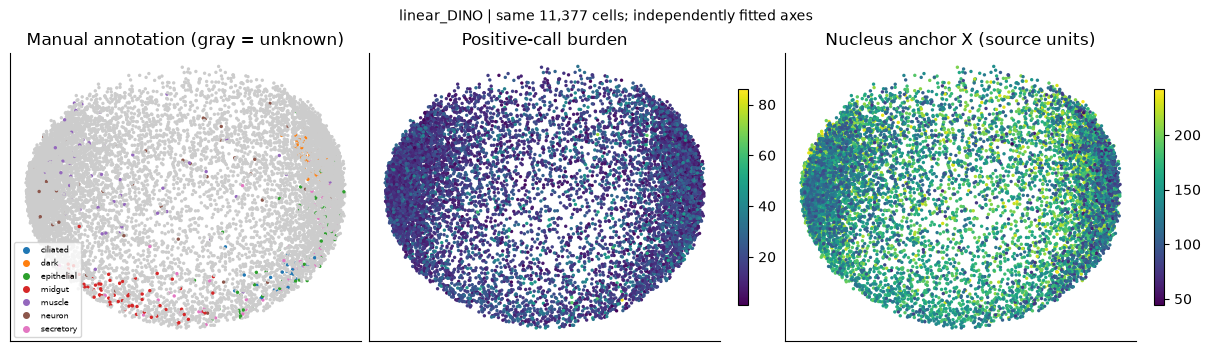

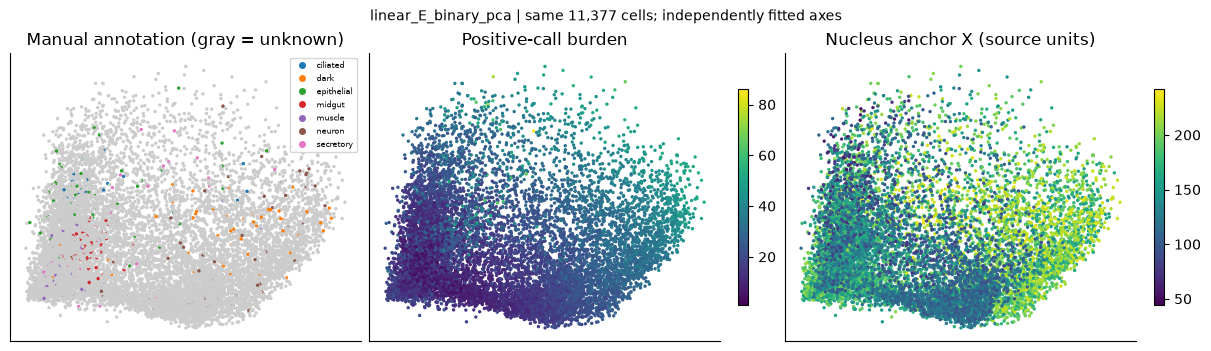

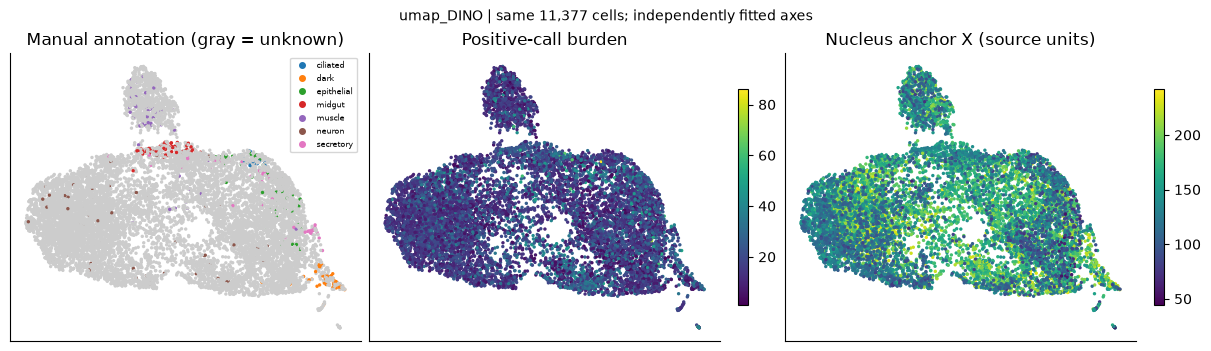

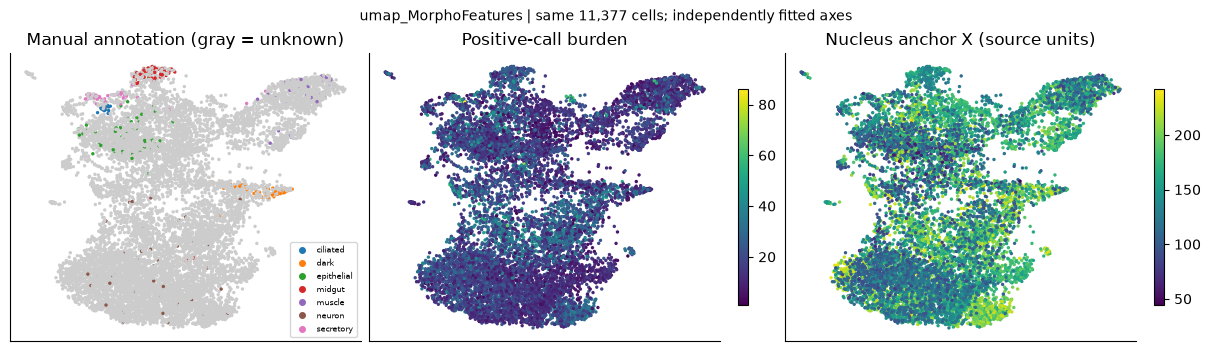

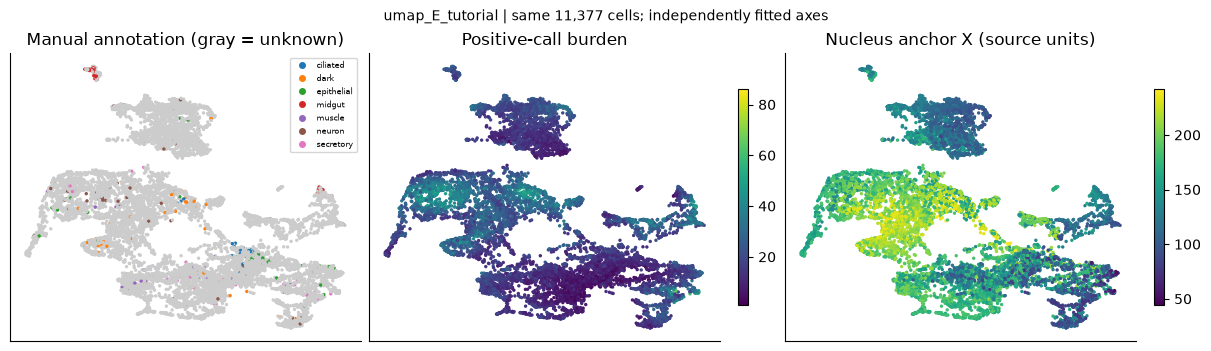

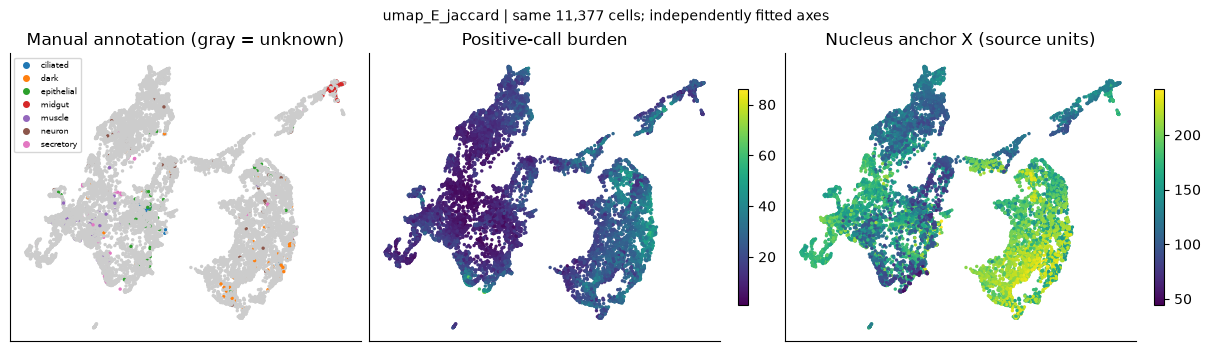

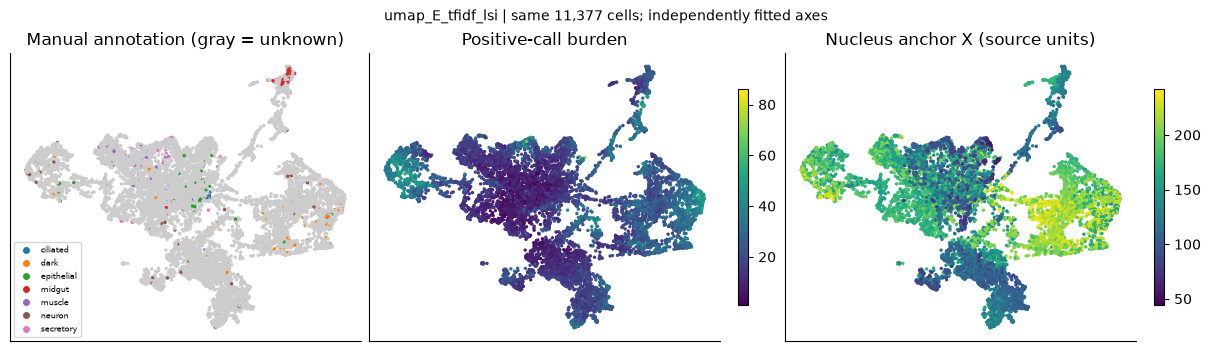

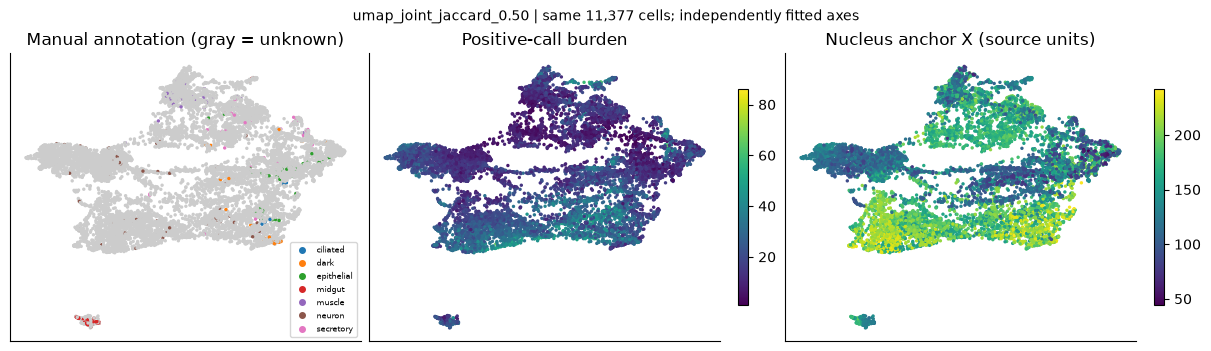

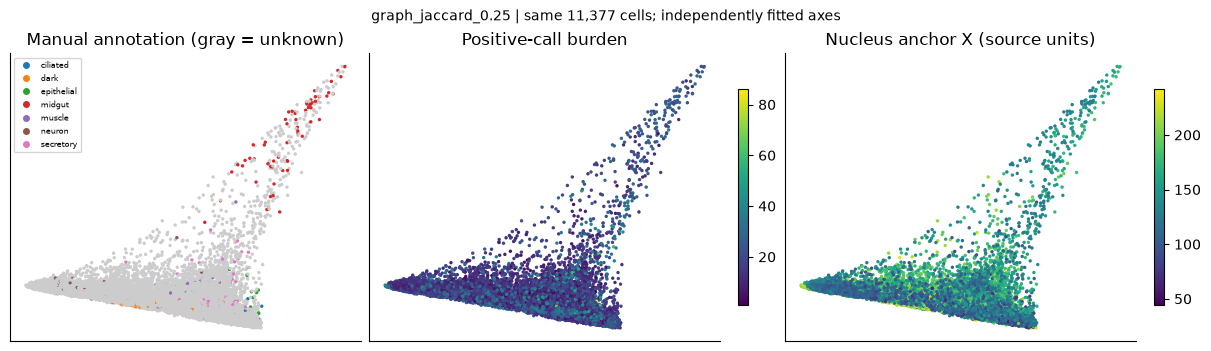

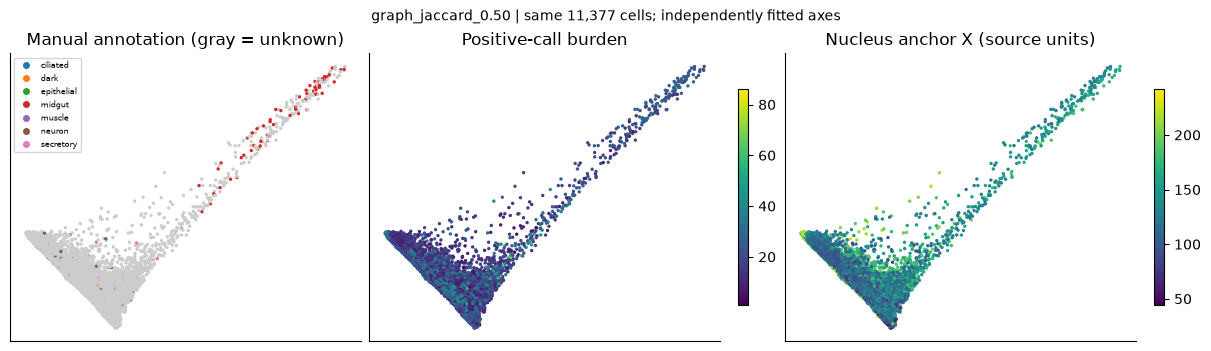

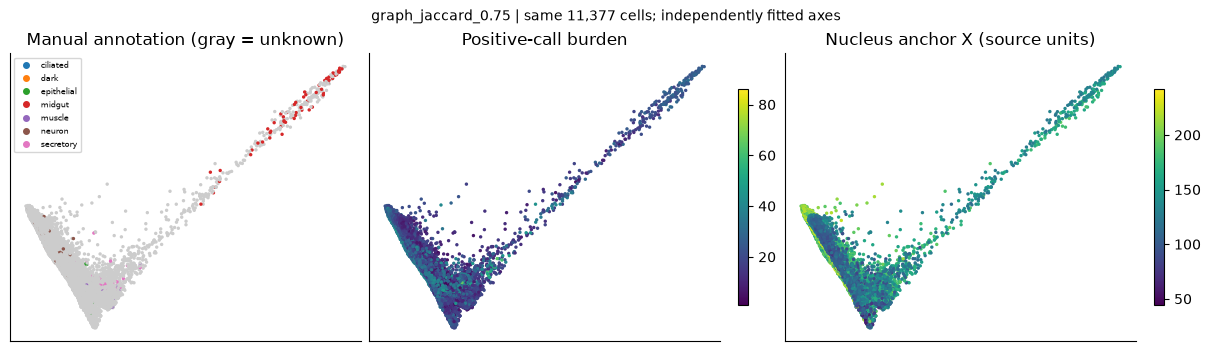

,layout,trustworthiness,neighbor_retention
0,umap_DINO,0.942,0.184
1,umap_MorphoFeatures,0.914,0.162
2,umap_E_tutorial,0.972,0.342
3,umap_E_jaccard,0.960,0.341
4,umap_E_tfidf_lsi,0.951,0.312
5,umap_joint_jaccard_0.50,0.950,0.276


In [12]:
layouts = {}
# Plain linear reference on two balanced latent spaces.
for name in ('DINO', 'E_binary_pca'):
    layouts['linear_'+name] = vectors[name][subset, :2]
layout_scores = []
def assess_layout(name, xy, d):
    return {'layout':name, 'trustworthiness':trustworthiness(d, xy, n_neighbors=k, metric='precomputed'),
            'neighbor_retention':overlap(nearest(d), nearest(pairdist(xy)))}
if RUN_UMAP:
    import umap
    for name in UMAP_NAMES:
        if name not in distances: raise ValueError(f'Unknown UMAP_NAMES entry: {name}')
        xy = umap.UMAP(n_neighbors=k, min_dist=.15, metric='precomputed', init='random', random_state=SEED, n_jobs=1).fit_transform(distances[name])
        layouts['umap_'+name] = xy
        layout_scores.append(assess_layout('umap_'+name, xy, distances[name]))
if RUN_TSNE:
    target = 'joint_jaccard_0.50'
    xy = TSNE(n_components=2, metric='precomputed', init='random', perplexity=min(30, (n-1)/3), random_state=SEED, learning_rate='auto').fit_transform(distances[target])
    layouts['tsne_'+target] = xy
    layout_scores.append(assess_layout('tsne_'+target, xy, distances[target]))
layouts.update(graph_layouts)

classes = sorted(labels.dropna().astype(str).unique())
class_colors = {label: plt.get_cmap('tab10')(j % 10) for j,label in enumerate(classes)}
colors = [class_colors.get(str(v), (.8,.8,.8,1)) if pd.notna(v) else (.8,.8,.8,1) for v in labels.iloc[subset]]
from matplotlib.lines import Line2D
for name, xy in layouts.items():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), layout='constrained')
    ax[0].scatter(*xy.T, c=colors, s=6, linewidths=0, rasterized=True)
    ax[0].set_title('Manual annotation (gray = unknown)')
    for a, value, title in [(ax[1], E[subset].sum(1), 'Positive-call burden'), (ax[2], XYZ[subset,0], 'Nucleus anchor X (source units)')]:
        artist = a.scatter(*xy.T, c=value, s=6, linewidths=0, cmap='viridis', rasterized=True)
        fig.colorbar(artist, ax=a, shrink=.75); a.set_title(title)
    ax[0].legend(handles=[Line2D([],[],marker='o',linestyle='',color=class_colors[c],label=c,markersize=4) for c in classes], fontsize=6, loc='best')
    for a in ax: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(name + f' | same {n:,} cells; independently fitted axes', fontsize=10)
    figure(fig, slug(name))
    table(pd.DataFrame({'cell_id':gids, 'nucleus_id':gnuc, 'x':xy[:,0], 'y':xy[:,1]}), slug(name)+'_coordinates')
table(pd.DataFrame(layout_scores), 'layout_quality')
display(pd.DataFrame(layout_scores).round(3))

/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


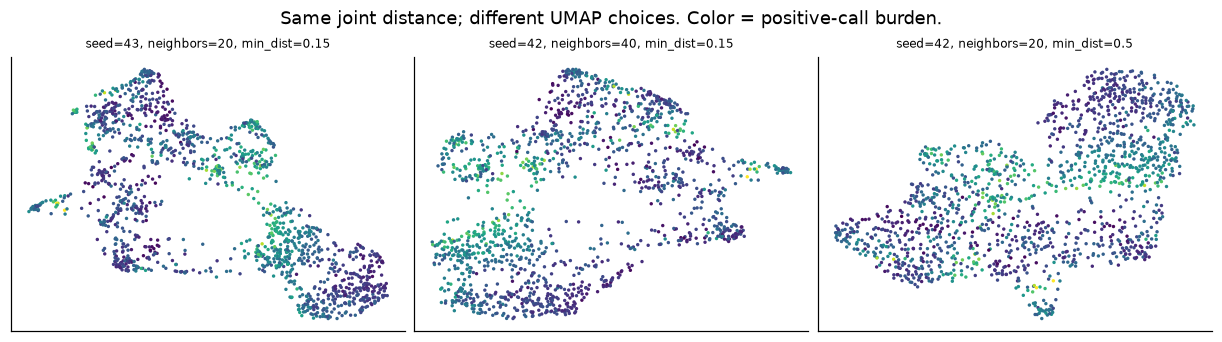

,layout,trustworthiness,neighbor_retention,seed,n_neighbors,min_dist,layout_neighbor_overlap_to_default
0,sensitivity_seed43_k20_min0.15,0.940,0.398,43,20,0.15,0.632
1,sensitivity_seed42_k40_min0.15,0.933,0.364,42,40,0.15,0.560
2,sensitivity_seed42_k20_min0.5,0.921,0.346,42,20,0.50,0.578


In [7]:
sensitivity_rows = []
if RUN_UMAP and RUN_LAYOUT_SENSITIVITY:
    name = 'joint_jaccard_0.50'
    d = distances[name]
    reference = layouts.get('umap_'+name)
    if reference is None:
        reference = umap.UMAP(n_neighbors=k, min_dist=.15, metric='precomputed', init='random', random_state=SEED, n_jobs=1).fit_transform(d)
    ref_neighbors = nearest(pairdist(reference))
    variants = [(SEED+1, k, .15), (SEED, min(2*k,n-1), .15), (SEED, k, .5)]
    fig, axes = plt.subplots(1, len(variants), figsize=(11,3), layout='constrained')
    for ax, (seed, nn, mdist) in zip(axes, variants):
        xy = umap.UMAP(n_neighbors=nn, min_dist=mdist, metric='precomputed', init='random', random_state=seed, n_jobs=1).fit_transform(d)
        tag = f'sensitivity_seed{seed}_k{nn}_min{mdist}'
        row = assess_layout(tag, xy, d)
        row.update(seed=seed, n_neighbors=nn, min_dist=mdist, layout_neighbor_overlap_to_default=overlap(ref_neighbors, nearest(pairdist(xy))))
        sensitivity_rows.append(row)
        table(pd.DataFrame({'cell_id':gids,'nucleus_id':gnuc,'x':xy[:,0],'y':xy[:,1]}), tag)
        ax.scatter(*xy.T, c=E[subset].sum(1), vmin=E[subset].sum(1).min(), vmax=E[subset].sum(1).max(), s=5, linewidths=0, cmap='viridis')
        ax.set_title(f'seed={seed}, neighbors={nn}, min_dist={mdist}', fontsize=8); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle('Same joint distance; different UMAP choices. Color = positive-call burden.')
    figure(fig, 'layout_sensitivity')
table(pd.DataFrame(sensitivity_rows), 'layout_sensitivity')
if sensitivity_rows: display(pd.DataFrame(sensitivity_rows).round(3))

## 7. Does a representation help held-out manual-label prediction?

Use the **same annotated cells and folds** for all recipes: both morphology baselines, expression alone, balanced latent fusion, and the original full-vector fusion. Models use fixed logistic regression settings; feature masks, prevalence weights, normalization, PCA/SVD and block balancing are all fitted on training cells only. Two controls are included: training-majority label and nucleus position alone (linear classifier; not an exhaustive spatial model).

Random folds keep known bilateral pairs together. Spatial folds hold out coordinate-derived regions; their bilateral crossings and missing training classes are reported. These tests measure interpolation and spatial transfer within one animal; they are not independent-specimen tests. Fixed encoders may already have seen this animal in unsupervised training. The small manual-label set and its annotation provenance limit claims about molecular identities.

This evaluates deployable **vector** recipes. Distance/graph methods are assessed descriptively above, not given an inductive score using a graph already fitted on test cells. Predicting expression from morphology is another task: see the original notebook or [full_expression_prediction_tutorial.ipynb](full_expression_prediction_tutorial.ipynb). A gene used in fusion cannot also be an independent prediction target; remove it (and consider correlated marker blocks) and refit within folds.

Scores are exploratory. Choosing the best method/weight/dimension from these results requires nested selection or a new confirmation set before reporting unbiased accuracy. Do not rank scientific conclusions by UMAP appearance.

In [8]:
cv_scores, cv_predictions, fold_rows = [], [], []
if RUN_CLASSIFICATION:
    symmetry = pd.read_csv(CELL_TABLE_ROOT/'symmetric_cells.tsv', sep='\t', dtype=str)
    symmetry['label_id'] = exact_ids(symmetry.label_id)
    symmetry = symmetry.loc[symmetry.label_id > 0]
    if not symmetry.label_id.is_unique: raise ValueError('Duplicate nonbackground bilateral cell IDs.')
    pairs = symmetry.set_index('label_id').pair_index.reindex(ids)
    pair_groups = np.array([f'pair:{int(Decimal(p))}' if pd.notna(p) and Decimal(p)>0 else f'cell:{cell}' for cell,p in zip(ids,pairs)])
    regions = KMeans(n_clusters=min(SPATIAL_REGIONS,len(ids)), n_init=10, random_state=SEED).fit_predict(XYZ)
    table(pd.DataFrame({'cell_id':ids,'nucleus_id':nucleus_ids,'anchor_x':XYZ[:,0],'anchor_y':XYZ[:,1],'anchor_z':XYZ[:,2],
                        'spatial_region':regions,'pair_group':pair_groups}), 'spatial_and_pair_groups')
    annotated = np.flatnonzero(labels.notna())
    y = labels.iloc[annotated].astype(str).to_numpy()
    if len(np.unique(y)) < 2: raise ValueError('Need at least two manual classes.')
    dummy = np.zeros((len(y),1))
    splits = {
        'random_pair_grouped': list(StratifiedGroupKFold(n_splits=CLASSIFIER_FOLDS, shuffle=True, random_state=SEED).split(dummy,y,pair_groups[annotated])),
        'spatial': list(GroupKFold(n_splits=CLASSIFIER_FOLDS).split(dummy,y,regions[annotated]))}
    for scheme, folds in splits.items():
        prediction_sets = {}
        for fold,(tr,te) in enumerate(folds):
            train, test = annotated[tr], annotated[te]
            group = pair_groups if scheme=='random_pair_grouped' else regions
            assert not set(group[train]) & set(group[test])
            if len(np.unique(y[tr])) < 2: raise ValueError(f'{scheme} fold {fold}: fewer than two training classes.')
            for pos in test:
                fold_rows.append({'scheme':scheme,'fold':fold,'cell_id':int(ids[pos]),'nucleus_id':int(nucleus_ids[pos]),
                    'train_missing_classes':','.join(sorted(set(y)-set(y[tr]))),
                    'bilateral_groups_crossing_fold':len(set(pair_groups[train]) & set(pair_groups[test]))})
            train_blocks, test_blocks = {}, {}
            for name,X in X_morph.items():
                model = MorphologyMap().fit(X[train])
                a,b = model.transform(X[train]),model.transform(X[test])
                scale = RMSBlock().fit(a)
                train_blocks[name], test_blocks[name] = scale.transform(a), scale.transform(b)
            for method in CV_EXPRESSION_METHODS:
                name = 'E_'+method
                model = ExpressionMap(method).fit(E[train])
                a,b = model.transform(E[train]),model.transform(E[test])
                scale = RMSBlock().fit(a)
                train_blocks[name], test_blocks[name] = scale.transform(a),scale.transform(b)
                for w in CV_WEIGHTS:
                    joint = f'joint_{method}_{w:.2f}'
                    train_blocks[joint] = np.column_stack([np.sqrt(1-w)*train_blocks[MORPHOLOGY_FOR_FUSION],np.sqrt(w)*train_blocks[name]])
                    test_blocks[joint] = np.column_stack([np.sqrt(1-w)*test_blocks[MORPHOLOGY_FOR_FUSION],np.sqrt(w)*test_blocks[name]])
            a = TutorialBlock().fit(X_morph[MORPHOLOGY_FOR_FUSION][train])
            b = TutorialBlock().fit(E[train])
            train_blocks['tutorial_full_joint_0.50'] = np.column_stack([np.sqrt(.5)*a.transform(X_morph[MORPHOLOGY_FOR_FUSION][train]),np.sqrt(.5)*b.transform(E[train])])
            test_blocks['tutorial_full_joint_0.50'] = np.column_stack([np.sqrt(.5)*a.transform(X_morph[MORPHOLOGY_FOR_FUSION][test]),np.sqrt(.5)*b.transform(E[test])])
            pos_scale = StandardScaler().fit(XYZ[train])
            train_blocks['Position_linear'],test_blocks['Position_linear'] = pos_scale.transform(XYZ[train]),pos_scale.transform(XYZ[test])
            majority = pd.Series(y[tr]).value_counts().index[0]
            fold_predictions = {'Majority':np.repeat(majority,len(te))}
            for name,a in train_blocks.items():
                clf = LogisticRegression(C=LOGISTIC_C,class_weight='balanced',max_iter=3000,random_state=SEED).fit(a,y[tr])
                fold_predictions[name] = clf.predict(test_blocks[name])
            for name,pred in fold_predictions.items():
                if name not in prediction_sets: prediction_sets[name] = np.empty(len(y),dtype=object)
                prediction_sets[name][te] = pred
                for pos,observed,predicted in zip(test,y[te],pred):
                    cv_predictions.append({'scheme':scheme,'fold':fold,'representation':name,'cell_id':int(ids[pos]),
                        'nucleus_id':int(nucleus_ids[pos]),'observed':observed,'predicted':predicted})
        for name,pred in prediction_sets.items():
            cv_scores.append({'scheme':scheme,'representation':name,'cells':len(y),'balanced_accuracy':balanced_accuracy_score(y,pred),
                'macro_f1':f1_score(y,pred,average='macro',zero_division=0)})
    table(pd.DataFrame(fold_rows),'classification_folds')
    table(pd.DataFrame(cv_predictions),'classification_oof_predictions')
    table(pd.DataFrame(cv_scores),'classification_scores')
    display(pd.DataFrame(cv_scores).round(3))

,scheme,representation,cells,balanced_accuracy,macro_f1
0,random_pair_grouped,Majority,390,0.143,0.066
1,random_pair_grouped,DINO,390,0.924,0.924
2,random_pair_grouped,MorphoFeatures,390,0.971,0.971
3,random_pair_grouped,E_tutorial,390,0.776,0.778
4,random_pair_grouped,joint_tutorial_0.50,390,0.967,0.965
5,random_pair_grouped,E_binary_pca,390,0.783,0.784
6,random_pair_grouped,joint_binary_pca_0.50,390,0.969,0.968
7,random_pair_grouped,E_tfidf_lsi,390,0.790,0.792
8,random_pair_grouped,joint_tfidf_lsi_0.50,390,0.971,0.970
9,random_pair_grouped,tutorial_full_joint_0.50,390,0.969,0.968


## 8. What to try next, and how to choose

**My starting recommendation for this dataset:** retain the original centered binary baseline; compare it with Jaccard neighborhoods and TF–IDF/LSI as explicit alternatives; combine each with morphology using prespecified weights. Prefer a method that has useful loadings, stable neighborhoods, tolerable dependence on burden, and consistent held-out performance. Rare calls and repeated profiles matter particularly with a 201-marker panel. A highly expressed biological program can create legitimate burden variation, so “least burden-correlated” is not itself a selection objective.

| Extension | When it helps | How to combine with morphology / validate |
|---|---|---|
| Logistic PCA / Bernoulli matrix factorization | Model the probability of binary detections directly | Fuse its latent scores using the same block balancing. Choose rank and regularization by held-out Bernoulli deviance against gene-prevalence predictions; evaluate new-cell inference separately from fitting latent scores to all cells. [Original logistic PCA study](https://proceedings.mlr.press/r4/schein03a.html). |
| MOFA2, Bernoulli expression + Gaussian morphology | Seek interpretable shared and modality-specific factors | Use paired cell rows with explicit view likelihoods; inspect explained variation/loadings for both views. Non-Gaussian inference uses approximations; held-out predictions and rank checks remain necessary. [MOFA2 likelihoods and caveats](https://biofam.github.io/MOFA2/faq.html). |
| WNN | Different cells have different relative modality quality | Supply separately processed paired reductions, inspect learned weights against burden/QC, and compare with the fixed graph blend here. Use the maintained Seurat implementation for a claim about WNN. |
| Regularized CCA / PLS | Ask specifically about cross-modal shared directions | Fit on paired training cells; regularize and measure cross-modal association on held-out cells. Shared-only objectives can suppress useful modality-specific biology. High training correlation is not sufficient. |
| NMF / topic-like models | Seek additive positive gene programs | Useful descriptive alternatives; standard reconstruction/KL losses are not automatically Bernoulli likelihoods. They require nonnegative inputs, so cannot be applied unchanged to signed morphology vectors. |
| Diffusion maps | A plausible continuous progression is of interest | Build on a defensible expression/joint graph and check diffusion-time sensitivity. Continuity in registered anatomy is not automatically developmental pseudotime. |
| Raw-count PCA/residuals/scVI | Raw UMI counts become available for the cells actually being modeled | Analyze the separate RNA reference in its own namespace. For cross-dataset mapping use shared genes and a validated mapping design; this does not create paired measurements in the EM specimen. |

These extensions are discussed, **not silently substituted for the runnable baselines**. Additional packages and careful model selection would be needed. The notebook does not fit Bernoulli factors, MOFA2, WNN, CCA or count models.

**Useful interpretation checks:**

- Large Jaccard-versus-Hamming differences mean that the evidential value of shared absence matters. Inspect marker sets for discordant neighborhoods.
- LSI correlated with burden calls for QC/source inspection and an explicit `LSI_DROP_FIRST` sensitivity run, not automatic component removal.
- Joint neighbors that mostly reproduce one modality at every weight suggest a scaling or redundant-information issue; inspect both neighborhood overlaps.
- Improved manual-label scores support usefulness for those annotations. They do not establish more accurate spatial expression, new molecular information, or cross-animal transfer.
- Repeat with `MORPHOLOGY_FOR_FUSION='MorphoFeatures'`; its shape/texture inputs differ from DINO's stored nuclear-patch inputs. Compare preprocessing recipes, not just encoder names.
- Run separate 15/30/50-dimensional and gene-prevalence/threshold sensitivity analyses before selecting a final recipe. Recover continuous spatial measurements and threshold/source provenance when possible; binary data cannot reconstruct lost abundance.

The original notebook's saved scores used a different PCA/fold recipe. Numerical differences from this notebook therefore cannot be attributed solely to a new expression method. Within-notebook matched comparisons are the meaningful ones.

In [9]:
source_paths = [SOURCE_NOTEBOOK, EXPRESSION_PATH, DINO_PATH, MORPHO_PATH, MANUAL_PATH,
                CELL_TABLE_ROOT/'cells_to_nuclei.tsv', CELL_TABLE_ROOT/'symmetric_cells.tsv', NUCLEUS_PATH]
fingerprints = [{'path':str(p),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in source_paths]
metadata_path = DINO_PATH.with_suffix('.metadata.json')
dino_metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else None
if metadata_path.exists(): fingerprints.append({'path':str(metadata_path),'bytes':metadata_path.stat().st_size,'sha256':sha256(metadata_path)})
config_keys = ['SEED','CPU_THREADS','MAX_GEOMETRY_CELLS','MAX_DISTANCE_GIB','LATENT_DIM','N_NEIGHBORS',
    'EXPRESSION_WEIGHTS','MORPHOLOGY_FOR_FUSION','EXPRESSION_VECTOR_METHODS','LSI_DROP_FIRST','UMAP_NAMES',
    'RUN_UMAP','RUN_LAYOUT_SENSITIVITY','RUN_TSNE','RUN_CLASSIFICATION','CLASSIFIER_FOLDS','SPATIAL_REGIONS',
    'LOGISTIC_C','CV_EXPRESSION_METHODS','CV_WEIGHTS']
manifest = {'schema':'binary_expression_methods.v1','run_id':RUN_ID,'python':platform.python_version(),
    'versions':versions,'settings':{key:globals()[key] for key in config_keys},'sources':fingerprints,
    'dino_source_metadata':dino_metadata,'matched_cells':len(ids),'geometry_cells':n,'annotated_cells':int(labels.notna().sum()),
    'identity':{'expression':'nucleus_id','vectors':'label_ids = cell IDs; separate nucleus_ids','graphs':'row order in tables/geometry_cohort.tsv'},
    'fit_scope':{'vectors_models':'all matched nonempty cells; descriptive','distances_graphs_layouts':'one saved random cohort; transductive',
                 'classification':'training folds only, on annotated cells; fixed encoder'},
    'coordinate_metadata':{'source':str(NUCLEUS_PATH),'columns':['anchor_x','anchor_y','anchor_z'],
        'frame':'source PlatyBrowser nucleus table','units':'source units; not independently verified here','voxel_conversion':None},
    'vector_preprocessing':'see section 3; latent blocks centered and RMS-balanced; tutorial_full_joint uses full centered row-normalized blocks',
    'tfidf_formula':'log1p(1e4 * row_L1_binary * log1p(n_train / (1 + training_positive_cells)))',
    'limitations':['single paired EM animal','registered calls, not sequenced EM cells','upstream source/threshold provenance incomplete',
        'manual labels limited; annotation independence unverified','binary distance ties','subsampled graph search population',
        'multiple exploratory comparisons, no untouched recipe-selection test','graph blend is not WNN']}
write_json(manifest, OUT/'provenance.json')
# Full-vector baseline transforms are also retained as numeric arrays, without pickle.
a = TutorialBlock().fit(X_morph[MORPHOLOGY_FOR_FUSION]); b = TutorialBlock().fit(E)
np.savez_compressed(OUT/'models'/'tutorial_full_joint_0_50_descriptive.npz',
    morphology_keep=a.keep_, morphology_mean=a.mean_, expression_keep=b.keep_, expression_mean=b.mean_, expression_columns=expr.columns.to_numpy(dtype=str))
report = [f'# Binary expression methods: run {RUN_ID}',
    f'{len(ids):,} matched cells; {n:,} in the geometry sample; {labels.notna().sum()} manual annotations.',
    'See provenance.json for settings, source hashes, identity namespaces, fit scopes and limitations.',
    '## Neighborhood diagnostics', neighbor_scores.to_string(index=False),
    '## Manual-label exploratory cross-validation', pd.DataFrame(cv_scores).to_string(index=False) if cv_scores else 'Disabled.',
    '## Reading the outputs',
    'vectors/: full-cohort numeric representations (not 2D coordinates); label_ids are cell IDs, nucleus_ids are separate. '
    'models/: numeric descriptive transforms, not classifiers or validation fits. Expression feature order is recorded below. '
    'tables/: QC, gene loadings, distance scales, sample IDs, layout coordinates, neighborhood scores, fold membership and held-out predictions. '
    'graphs/: sparse affinities in geometry_cohort.tsv row order. figures/: PNG/SVG. '
    'A classifier was evaluated inside folds, not saved as a deployment model. Graph/UMAP maps describe only the sampled cohort.',
    'Do not choose a final method from plot separation alone. Compare burden, ties, modality retention and held-out tasks; confirm the selected recipe independently.']
(OUT/'findings.txt').write_text('\n\n'.join(report)+'\n')
write_json({'expression_columns':expr.columns.tolist(),'vector_names':list(vectors),
    'morphology_for_fusion':MORPHOLOGY_FOR_FUSION,'model_use':'Numeric descriptive parameters; recreate the matching classes/formula in this notebook.'}, OUT/'models'/'feature_schema.json')
print('Finished:', OUT)
print('Source notebook unchanged. New results are descriptive except the explicitly held-out classifier predictions.')

Finished: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/binary_expression_methods/20261009-134247-780778
Source notebook unchanged. New results are descriptive except the explicitly held-out classifier predictions.


## 9. Reusing the results

Change settings in section 1 and rerun from a fresh kernel to create a new run. Increase the geometry cohort only after reviewing the explicit memory estimate; matrix storage grows quadratically. `RUN_UMAP=False` leaves vector, distance, graph and classification analyses available. `RUN_CLASSIFICATION=False` gives a quicker unsupervised exploration.

For inspection/MoBIE, join coordinate tables on `cell_id` for a cell segmentation or on `nucleus_id` for a nucleus segmentation. Graph NPZ files are affinities and must not be passed off as feature vectors. UMAP, t-SNE and graph coordinates are layouts rather than new measurements. Keep each run's manifest and cohort file beside its exports.